In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Retrieve a simulated single-cycle deep-UV pulse with two forward models.

The dataset (``examples/data/tgfrog_sim_rdw_duv.h5``) is a reduced cut of the
first-principles 3D TG-FROG instrument simulation made with ModelPNPS.jl
(https://github.com/LupoLab/ModelPNPS.jl). The input is the resonant dispersive
wave (RDW) emitted by a simulated hollow-capillary-fibre source: a ~1 fs
deep-UV pulse with a structured spectrum and trailing satellites. It is
recorded as a measurement would be, here after 9.5 um of fused silica and
through the open 2.0 mm collection hole. Nothing in the trace comes from
croak's own forward model.

The same trace is retrieved twice:

* with the **extended model**: dispersive propagation through the substrate
  plus the geometric BOXCARS smearing kernel, with the kernel scale and the
  delay zero fitted from the data;
* with the **standard thin-medium model** that conventional FROG codes use.

The reference pulse, drawn as the grey fill, is the mask-vignetted gate
beamlet stored in the file (1.06 fs). The extended model recovers it (the
script prints 1.17 fs at a trace error of 0.05 %), including the satellites
and the structured spectrum. The standard model also fits the trace well
(0.25 %) but returns a smooth pulse of 2.64 fs, about 2.5 times too long: the
trace error alone does not certify a retrieval.

The preprocessing here (defringing, a fixed fourth-power spectral correction,
the integrated beamlet spectrum, fitted delay zero and smearing scale) is a
teaching set-up; the papers' validation uses a different protocol, described
in the manual's validation chapter.

Run::

    uv run python examples/example_paper_rdw.py

Takes a few minutes (two retrievals on a 400-point grid). Writes
``paper_rdw.png``.
"""

from __future__ import annotations

import matplotlib
import numpy as np

matplotlib.use("Agg")

import matplotlib.pyplot as plt  # noqa: E402 - must follow matplotlib.use above

import croak  # noqa: E402 - imports pyplot transitively
from croak.session import (  # noqa: E402 - see note above
    PreprocParams,
    RetrieveParams,
    SimulatedLoadParams,
    assemble_simulated_load_data,
    build_tracedata,
    run_retrieval,
)

DATA = "examples/data/tgfrog_sim_rdw_duv.h5"
Z_UM = 9.5
REFERENCE_FWHM_FS = 1.06  # the stored mask-vignetted gate beamlet

# The retrieval band for this scan (the RDW spectrum reaches further to the red
# than the Gaussian test pulse), with the delay crop at the scan's uniform core.
PREPROC = PreprocParams(
    lam_min_nm=148.0,
    lam_max_nm=830.0,
    lam_bound_min_nm=74.0,
    lam_bound_max_nm=1245.0,
    trange_fs=150.0,
    tau_min_fs=-38.0,
    tau_max_fs=38.0,
    lamm_min_nm=148.0,
    lamm_max_nm=830.0,
    lamm_bound_min_nm=148.0,
    lamm_bound_max_nm=830.0,
    taum_min_fs=-38.0,
    taum_max_fs=38.0,
    tau_bound_min_fs=-38.0,
    tau_bound_max_fs=38.0,
    defringe=True,
)


def main() -> None:
    """Retrieve with both models and plot them against the reference pulse."""
    sim = SimulatedLoadParams(
        frog_path=DATA,
        z_thickness_um=Z_UM,
        lam_min_nm=148.0,
        lam_max_nm=830.0,
        third_order=True,
        third_order_exp=4.0,
        use_spectrum=True,
        spectrum_source="beamlet",
    )
    data = assemble_simulated_load_data(sim)
    td = build_tracedata(PREPROC, data)
    reference = data["truth"]  # the stored gate-beamlet reference pulse

    extended = RetrieveParams(
        solver="warm-lbfgs",
        maxiters=300,
        dispersive=True,
        material="SiO2",
        thickness_um=Z_UM,
        npoints=10,
        smearing=True,
        smear_hole_diameter_mm=1.0,
        smear_hole_spacing_mm=1.0,
        fit_smearing=True,  # the kernel scale is fitted from the data
        fit_tau0=True,
    )
    standard = RetrieveParams(solver="warm-lbfgs", maxiters=300)

    out = {}
    for label, rp in (("extended (fitted kernel)", extended), ("standard", standard)):
        res = run_retrieval(rp, td, rng=np.random.default_rng(0))
        pr = croak.process_result(res, measured=td.trace)
        out[label] = pr
        print(
            f"{label:24s}  R = {100 * res.error:.3f}%  "
            f"FWHM = {pr.fwhm_retr * 1e15:.2f} fs  (reference {REFERENCE_FWHM_FS} fs)"
        )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")

    ax1.fill_between(
        reference.t * 1e15, reference.It, color="0.8", label="reference pulse"
    )
    for label, style in zip(out, ("-", "--"), strict=True):
        pr = out[label]
        t0 = pr.t_over[pr.It_retr.argmax()]
        ax1.plot((pr.t_over - t0) * 1e15, pr.It_retr, style, label=label)
    ax1.set_xlim(-6, 12)
    ax1.set_xlabel("time (fs)")
    ax1.set_ylabel("intensity (norm.)")
    ax1.legend()

    if reference.lam is not None:
        ax2.fill_between(
            reference.lam * 1e9, reference.Iw, color="0.8", label="reference spectrum"
        )
    for label, style in zip(out, ("-", "--"), strict=True):
        pr = out[label]
        ax2.plot(pr.wavelength * 1e9, pr.Ilam, style, label=label)
    ax2.set_xlim(200, 340)
    ax2.set_xlabel("wavelength (nm)")
    ax2.set_ylabel("spectral intensity (norm.)")
    ax2.legend()

    fig.savefig("paper_rdw.png", dpi=150)
    print("wrote paper_rdw.png")


if __name__ == "__main__":
    main()


extended (fitted kernel)  R = 0.049%  FWHM = 1.17 fs  (reference 1.06 fs)


standard                  R = 0.246%  FWHM = 2.64 fs  (reference 1.06 fs)
wrote paper_rdw.png


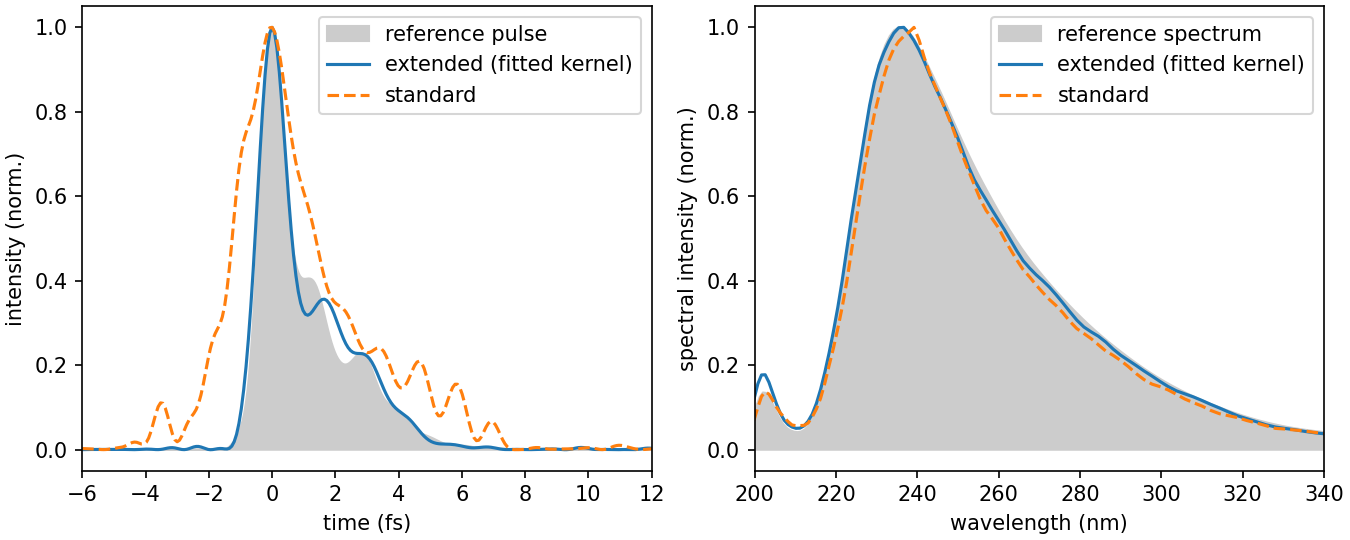

In [3]:
display(Image(filename="paper_rdw.png"))